# Session 9 lab: How sure are we?

<p class="lead">
Put an honest range around an average order value, then analyse a checkout-page experiment: check the randomisation, measure the lift, say how sure you are, and explain it to a manager without overselling it.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/09_sampling_and_experiments_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

Two managers each want a number they can act on:

> *Retail lead: "What is our average order value? I need a figure I can plan with, and I need to know how far off it might be."*
>
> *Marketing lead: "We tested a new checkout page for four weeks. Did it work, by how much, and should we roll it out?"*

A single number answers neither question honestly. Both need a **range** and a **plain-language explanation** of how sure we are.

> **About the data**
>
> **Superstore** is a sample published by Tableau about a **fictitious** company. Sales are in the file's own **source monetary units**; the currency is not stated.
>
> **`ab_test.csv`** is **synthetic** teaching data generated by the course: one row per visitor, randomly assigned to the current checkout page (**A**, control) or the new one (**B**, treatment) over 28 days. Revenue is in neutral **currency units**.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G5 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I7 |
| **Challenge** | Harder reasoning and debugging | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Aggregate order lines to orders before measuring average order value.
2. Simulate a sampling distribution and read its standard error.
3. Bootstrap a 95% confidence interval and compare it with the formula interval.
4. Check that an A/B test was randomised fairly.
5. Measure conversion, revenue per visitor and lift, with an interval and a permutation p-value.
6. Explain a confidence interval and an A/B result to a manager in plain language.
7. Show why peeking and slicing produce false winners.

**Evidence you keep:** a CI for AOV and an A/B result, each explained in plain language for a manager.

---

## Before you start

- Read the [Session 9 lecture](09_sampling_and_experiments_lecture.md).
- Re-read [How statistics can mislead](../foundations/misleading-statistics.md).

---

## Guided practice

### G1 (Core): From order lines to orders

Run both setup cells, then load the orders.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [3]:
import math

import numpy as np

df = load_orders()
print("Order lines:", len(df), "| different orders:", df["order_id"].nunique())

Order lines: 6815 | different orders: 3388


Average order value (**AOV**) is about **orders**, but each row is an order **line**. So we add up the lines of each order first. The last line of output shows what goes wrong if you skip this step.

In [4]:
orders = df.groupby("order_id")["sales"].sum()
values = orders.to_numpy()

print(f"Orders: {len(values)}")
print(f"AOV, all orders:       {values.mean():,.2f}")
print(f"Median order value:    {np.median(values):,.2f}")
print(f"Average LINE value:    {df['sales'].mean():,.2f}   <- wrong grain for AOV")

Orders: 3388
AOV, all orders:       466.64
Median order value:    151.46
Average LINE value:    231.98   <- wrong grain for AOV


> **A game we play in this lab**
>
> As in the lecture, we pretend these orders are the **whole population** of orders, so `values.mean()` is the **true AOV**. In real work you rarely see everything. Pretending lets us check whether our methods find the truth.

### G2 (Core): One sample, one answer

> **Your turn:** change the code in the next cell and run it again.

In [5]:
# 1. Run the cell. How far is the sample AOV from the true AOV?
# 2. Change seed to 2, then 3. Does the sample AOV change? Why?
# 3. Change sample_size to 25, then 400. Is the sampling error usually bigger or smaller?
seed = 1
sample_size = 100

rng = np.random.default_rng(seed)
sample = rng.choice(values, size=sample_size, replace=False)
true_aov = values.mean()

print(f"Sample of {sample_size} orders, AOV: {sample.mean():,.2f}")
print(f"True AOV:                       {true_aov:,.2f}")
print(f"Sampling error:                 {sample.mean() - true_aov:+,.2f}")

Sample of 100 orders, AOV: 542.07
True AOV:                       466.64
Sampling error:                 +75.43


### G3 (Core): Watch the sampling distribution form

Now repeat G2 a thousand times and keep every sample's AOV. The histogram of those AOVs is the **sampling distribution**. Its spread is the **standard error (SE)**.

> **Your turn:** change the code in the next cell and run it again.

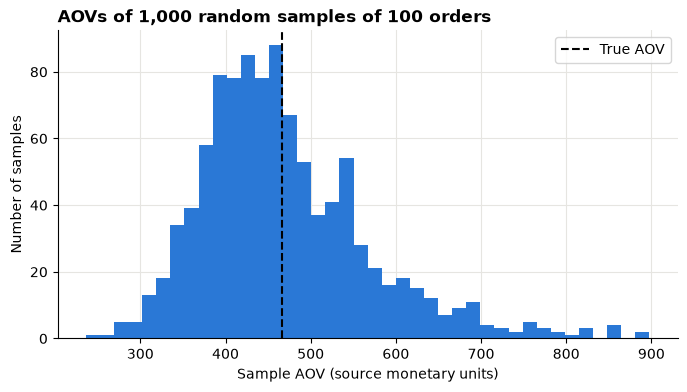

Average of the sample AOVs: 468.62  (true AOV 466.64)
Middle 95% of sample AOVs:  319 to 714
SE by simulation:           99.5
SD / sqrt(n):               97.5


In [6]:
# 1. Run the cell. Where is the histogram centred? How does its shape compare with single orders?
# 2. Compare "SE by simulation" with "SD / sqrt(n)". Are they close?
# 3. Change sample_size to 25, then 400. What happens to the width of the histogram and to the SE?
sample_size = 100
repeats = 1000

rng = np.random.default_rng(seed=1)
sample_aovs = np.array([rng.choice(values, size=sample_size, replace=False).mean()
                        for _ in range(repeats)])

ax = plt.gca()
ax.hist(sample_aovs, bins=40)
ax.axvline(true_aov, color="black", linestyle="--", label="True AOV")
ax.set_title(f"AOVs of {repeats:,} random samples of {sample_size} orders")
ax.set_xlabel("Sample AOV (source monetary units)")
ax.set_ylabel("Number of samples")
ax.legend()
plt.show()

low, high = np.percentile(sample_aovs, [2.5, 97.5])
print(f"Average of the sample AOVs: {sample_aovs.mean():,.2f}  (true AOV {true_aov:,.2f})")
print(f"Middle 95% of sample AOVs:  {low:,.0f} to {high:,.0f}")
print(f"SE by simulation:           {sample_aovs.std():,.1f}")
print(f"SD / sqrt(n):               {values.std() / math.sqrt(sample_size):,.1f}")

> **What do you notice?**
>
> Write down what happened to the SE when you made the sample four times bigger (from 25 to 100, or 100 to 400). Does that match the √n rule from the lecture?

### G4 (Core): Bootstrap a 95% confidence interval for AOV

In real work you have **one** sample. Here it is 200 orders. The bootstrap resamples **that sample**, with replacement, thousands of times, and the middle 95% of the resampled AOVs is the interval.

> **Your turn:** change the code in the next cell and run it again.

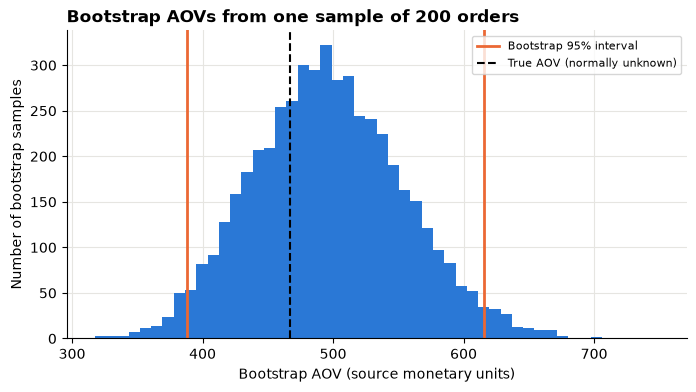

Sample AOV:          495.68
Bootstrap 95% CI:    388.22 to 615.58
Formula 95% CI:      383.40 to 607.96
Contains true AOV?   bootstrap True, formula True


In [7]:
# 1. Run the cell. Does each interval contain the true AOV? Are the two intervals close?
# 2. Change seed to 3, 6, 7, 8 and 9. Note each time whether the bootstrap interval contains the true AOV.
# 3. Change sample_size to 50. What happens to the width of the intervals?
seed = 2
sample_size = 200

rng = np.random.default_rng(seed)
my_sample = rng.choice(values, size=sample_size, replace=False)

boot_aovs = np.array([rng.choice(my_sample, size=sample_size, replace=True).mean()
                      for _ in range(5000)])
boot_low, boot_high = np.percentile(boot_aovs, [2.5, 97.5])

se = my_sample.std(ddof=1) / math.sqrt(sample_size)
formula_low, formula_high = my_sample.mean() - 1.96 * se, my_sample.mean() + 1.96 * se

ax = plt.gca()
ax.hist(boot_aovs, bins=50)
ax.axvline(boot_low, color="#eb6834", linewidth=2, label="Bootstrap 95% interval")
ax.axvline(boot_high, color="#eb6834", linewidth=2)
ax.axvline(true_aov, color="black", linestyle="--", label="True AOV (normally unknown)")
ax.set_title(f"Bootstrap AOVs from one sample of {sample_size} orders")
ax.set_xlabel("Bootstrap AOV (source monetary units)")
ax.set_ylabel("Number of bootstrap samples")
ax.legend(fontsize=8)
plt.show()

print(f"Sample AOV:          {my_sample.mean():,.2f}")
print(f"Bootstrap 95% CI:    {boot_low:,.2f} to {boot_high:,.2f}")
print(f"Formula 95% CI:      {formula_low:,.2f} to {formula_high:,.2f}")
print(f"Contains true AOV?   bootstrap {boot_low <= true_aov <= boot_high}, formula {formula_low <= true_aov <= formula_high}")

Over many seeds, about 95% of intervals should contain the true AOV (a little less with these very skewed order values, as the lecture showed). Any single interval may be one of the misses, and you cannot tell from inside it.

### G5 (Core): Explain the interval to the retail lead

Write two sentences in your evidence log, using **your** output from G4 with `seed = 2`:

> *"From a random sample of ___ orders, the average order value is ___ source monetary units. We are 95% confident that the average across all orders is between ___ and ___; a larger sample would narrow this range."*

Check your sentence against these rules:

- [ ] It says **orders**, not lines or customers.
- [ ] It gives the range, not just the single number.
- [ ] It does **not** say "95% of orders are between…" or "there is a 95% probability…".
- [ ] It states the units.

---

## Independent tasks

### I1 (Core): Load the test and check the randomisation

Before looking at any result, check the experiment itself: one row per visitor, the expected dates, and about half the visitors in each group, **within each device**.

> **Your turn:** change the code in the next cell and run it again.

In [8]:
# 1. Run the cell. Is there one row per visitor? Is about half of each device in B?
# 2. Change check_by to "date". Look at the smallest and largest daily share in B. Is any day far from 50%?
# 3. Write one sentence on whether the randomisation looks balanced.
ab = load_marketing("ab_test.csv")
print("Rows:", len(ab), "| distinct visitors:", ab["visitor_id"].nunique())
print("Test days:", ab["date"].min().date(), "to", ab["date"].max().date(), "|", ab["date"].nunique(), "days")

check_by = "device"
balance = ab.groupby(check_by).agg(visitors=("variant", "size"),
                                   share_in_B=("variant", lambda v: (v == "B").mean()))
print("Smallest share in B:", f"{balance['share_in_B'].min():.1%}",
      "| largest:", f"{balance['share_in_B'].max():.1%}")
balance.assign(share_in_B=balance["share_in_B"].map("{:.1%}".format))

Rows: 60000 | distinct visitors: 60000
Test days: 2025-03-03 to 2025-03-30 | 28 days
Smallest share in B: 50.2% | largest: 50.3%


,visitors,share_in_B
device,,
desktop,22650,50.3%
mobile,37350,50.2%


Also check the other way round: is the **device mix** the same in A and B?

In [9]:
pd.crosstab(ab["variant"], ab["device"], normalize="index").map("{:.1%}".format)

device,desktop,mobile
variant,,
A,37.7%,62.3%
B,37.8%,62.2%


> **Why this matters**
>
> Mobile and desktop visitors convert at different rates. If B had received many more desktop visitors, B could look better just because of its device mix. Random assignment should make the mix similar; the balance check confirms it did.

### I2 (Core): Conversion, revenue per visitor and lift

In [10]:
results = ab.groupby("variant").agg(
    visitors=("visitor_id", "count"),
    buyers=("converted", "sum"),
    revenue=("revenue", "sum"),
)
results["conversion_rate"] = results["buyers"] / results["visitors"]
results["revenue_per_visitor"] = results["revenue"] / results["visitors"]

for measure in ["conversion_rate", "revenue_per_visitor"]:
    a, b = results.loc["A", measure], results.loc["B", measure]
    unit = "percentage points" if measure == "conversion_rate" else "currency units per visitor"
    absolute = (b - a) * 100 if measure == "conversion_rate" else b - a
    print(f"{measure}: absolute lift {absolute:+.2f} {unit} | relative lift {(b - a) / a:+.1%}")

results.assign(
    revenue=results["revenue"].map("{:,.0f}".format),
    conversion_rate=results["conversion_rate"].map("{:.2%}".format),
    revenue_per_visitor=results["revenue_per_visitor"].map("{:.2f}".format),
)

conversion_rate: absolute lift +0.50 percentage points | relative lift +15.8%
revenue_per_visitor: absolute lift +0.41 currency units per visitor | relative lift +13.4%


,visitors,buyers,revenue,conversion_rate,revenue_per_visitor
variant,,,,,
A,29873,940,"92,066",3.15%,3.08
B,30127,1098,"105,280",3.64%,3.49


Revenue per visitor divides by **all** visitors, including the zeros of those who did not buy. It combines "more people buy" with "buyers spend more or less".

### I3 (Core): How sure are we? A confidence interval for the lift

The function below bootstraps the difference **B − A** in the average of any column: resample visitors within each group, recompute both averages, repeat. For a 0/1 column like `converted`, the average **is** the conversion rate.

In [11]:
def bootstrap_diff(data, column, reps=2000, seed=1):
    """95% bootstrap percentile interval for mean(B) - mean(A) of one column."""
    rng = np.random.default_rng(seed)
    a = data.loc[data["variant"] == "A", column].to_numpy()
    b = data.loc[data["variant"] == "B", column].to_numpy()
    diffs = np.array([rng.choice(b, size=len(b)).mean() - rng.choice(a, size=len(a)).mean()
                      for _ in range(reps)])
    return b.mean() - a.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


def compare_rates(buyers_a, visitors_a, buyers_b, visitors_b):
    """Lift (B - A), its 95% interval and a two-sided p-value, by the normal formula."""
    rate_a, rate_b = buyers_a / visitors_a, buyers_b / visitors_b
    lift = rate_b - rate_a
    se = math.sqrt(rate_a * (1 - rate_a) / visitors_a + rate_b * (1 - rate_b) / visitors_b)
    pooled = (buyers_a + buyers_b) / (visitors_a + visitors_b)
    se_null = math.sqrt(pooled * (1 - pooled) * (1 / visitors_a + 1 / visitors_b))
    z = lift / se_null
    return {"lift": lift, "low": lift - 1.96 * se, "high": lift + 1.96 * se,
            "p_value": math.erfc(abs(z) / math.sqrt(2))}

> **Your turn:** change the code in the next cell and run it again.

In [12]:
# 1. Run the cell. Does the interval include zero? What is the smallest lift that is still plausible?
# 2. Change seed to 2. Does the bootstrap interval move much?
# 3. Are the bootstrap and formula intervals close? Why would you expect that here?
seed = 1
lift, low, high = bootstrap_diff(ab, "converted", seed=seed)
formula = compare_rates(results.loc["A", "buyers"], results.loc["A", "visitors"],
                        results.loc["B", "buyers"], results.loc["B", "visitors"])

print(f"Lift in conversion: {lift * 100:+.2f} percentage points")
print(f"Bootstrap 95% CI:   {low * 100:+.2f} to {high * 100:+.2f} points")
print(f"Formula 95% CI:     {formula['low'] * 100:+.2f} to {formula['high'] * 100:+.2f} points")

Lift in conversion: +0.50 percentage points
Bootstrap 95% CI:   +0.20 to +0.77 points
Formula 95% CI:     +0.21 to +0.79 points


### I4 (Core): Could chance explain it? A permutation p-value

If the new page made no difference, the A/B labels would be arbitrary. Shuffle them, recompute the lift, and count how often a shuffled lift is at least as large (either direction) as the real one.

In [13]:
def permutation_p(data, column, reps=5000, seed=1):
    """Two-sided permutation p-value for mean(B) - mean(A) of one column."""
    rng = np.random.default_rng(seed)
    values = data[column].to_numpy()
    is_b = (data["variant"] == "B").to_numpy()
    observed = values[is_b].mean() - values[~is_b].mean()
    shuffled = np.empty(reps)
    for i in range(reps):
        labels = rng.permutation(is_b)
        shuffled[i] = values[labels].mean() - values[~labels].mean()
    extreme = int((np.abs(shuffled) >= abs(observed)).sum())
    return extreme, shuffled

> **Your turn:** change the code in the next cell and run it again.

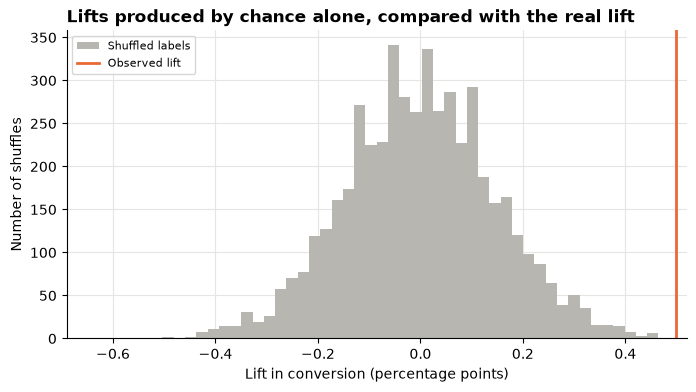

Shuffles at least as extreme: 1 of 5000
Permutation p-value:          0.0002
Formula p-value:              0.0008


In [14]:
# 1. Run the cell. How many shuffles reached the real lift? What is the p-value?
# 2. Change reps to 1000. Does the conclusion change? Why is the p-value rougher with fewer shuffles?
# 3. Compare with the formula p-value. Do they tell the same story?
reps = 5000
extreme, shuffled = permutation_p(ab, "converted", reps=reps)

ax = plt.gca()
ax.hist(shuffled * 100, bins=50, color="#b8b6b0", label="Shuffled labels")
ax.axvline(lift * 100, color="#eb6834", linewidth=2, label="Observed lift")
ax.set_title("Lifts produced by chance alone, compared with the real lift")
ax.set_xlabel("Lift in conversion (percentage points)")
ax.set_ylabel("Number of shuffles")
ax.legend(fontsize=8)
plt.show()

print(f"Shuffles at least as extreme: {extreme} of {reps}")
print(f"Permutation p-value:          {extreme / reps:.4f}" + ("  (below 1 in " + str(reps) + ")" if extreme == 0 else ""))
print(f"Formula p-value:              {formula['p_value']:.4f}")

### I5 (Core): The manager-ready sentence

Write **three sentences** for the marketing lead, using your outputs from I1–I4:

1. **What happened**, in business units: conversion on A and B, and the lift in percentage points (and, if you like, extra buyers per 10,000 visitors).
2. **How sure we are**: the 95% interval for the lift, and what the p-value says in plain words ("a gap this large would be very unlikely if the page made no difference").
3. **What it does not tell us**: for example, whether the lift is worth the cost of the new page, or whether it holds after the test period.

> **Avoid these phrases**
>
> "There is a 99.9% chance B is better." "The p-value proves the page works." "B increased conversion by 16%" (without saying it is a relative lift). "Statistically significant, so we must roll it out."

### I6 (Stretch): Revenue per visitor

Conversion is not the only thing that matters: the new page might bring more buyers who each spend less. Repeat I3 and I4 for **revenue per visitor**.

> **Your turn:** change the code in the next cell and run it again.

In [15]:
# 1. Run the cell. Is the interval for revenue per visitor wider or narrower, relative to its size, than for conversion?
# 2. Why is revenue per visitor noisier? (Hint: most visitors have 0, and buyers' order values vary.)
# 3. Write one sentence for the manager about revenue per visitor.
column = "revenue"
diff, low, high = bootstrap_diff(ab, column)
extreme, _ = permutation_p(ab, column, reps=2000)

print(f"Difference in {column} per visitor (B - A): {diff:+.2f} currency units")
print(f"Bootstrap 95% CI: {low:+.2f} to {high:+.2f}")
print(f"Permutation p-value: {extreme / 2000:.4f}" + ("  (below 1 in 2000)" if extreme == 0 else ""))

Difference in revenue per visitor (B - A): +0.41 currency units
Bootstrap 95% CI: +0.08 to +0.72
Permutation p-value: 0.0195


### I7 (Stretch): How sample size changes the interval

Suppose the test had stopped with only a fraction of its visitors. Take random subsets of 10%, 25%, 50% and 100% of visitors and compute the interval for the lift each time.

> **Your turn:** change the code in the next cell and run it again.

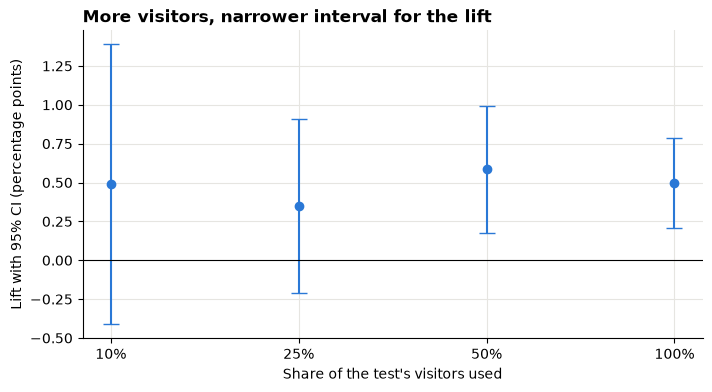

,visitors,lift (points),CI low,CI high,CI width
share of visitors,,,,,
10%,6030,0.49,-0.41,1.39,1.80
25%,14961,0.35,-0.21,0.91,1.12
50%,30035,0.58,0.18,0.99,0.82
100%,60000,0.50,0.21,0.79,0.58


In [16]:
# 1. Run the cell. How does the interval width change from 25% to 100% of the visitors?
# 2. Does that match the sqrt(n) rule (four times the data, half the width)?
# 3. Add 0.05 to the list of fractions. Would 5% of the visitors have been enough to decide?
fractions = [0.10, 0.25, 0.50, 1.00]

rng = np.random.default_rng(seed=1)
rows = []
for fraction in fractions:
    part = ab[rng.random(len(ab)) < fraction] if fraction < 1 else ab
    g = part.groupby("variant").agg(visitors=("converted", "size"), buyers=("converted", "sum"))
    r = compare_rates(g.loc["A", "buyers"], g.loc["A", "visitors"], g.loc["B", "buyers"], g.loc["B", "visitors"])
    rows.append({"share of visitors": f"{fraction:.0%}", "visitors": len(part),
                 "lift (points)": r["lift"] * 100, "CI low": r["low"] * 100,
                 "CI high": r["high"] * 100, "CI width": (r["high"] - r["low"]) * 100})
widths = pd.DataFrame(rows).set_index("share of visitors")

ax = plt.gca()
ax.errorbar(range(len(widths)), widths["lift (points)"],
            yerr=[widths["lift (points)"] - widths["CI low"], widths["CI high"] - widths["lift (points)"]],
            fmt="o", capsize=6)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(len(widths)), widths.index)
ax.set_title("More visitors, narrower interval for the lift")
ax.set_xlabel("Share of the test's visitors used")
ax.set_ylabel("Lift with 95% CI (percentage points)")
plt.show()
widths.round(2)

> **Planning a test**
>
> The width of the interval you can afford is decided **before** the test, by its sample size. If the lift that would matter to the business is smaller than half the interval width you expect, the test is too small to answer the question.

---

## Challenge

### C1 (Challenge): The daily peeker

A colleague says:

> *"I don't wait four weeks. I check the p-value every morning and stop the test the first day it drops below 0.05. Same answer, much faster."*

First look at the real test, day by day, as the colleague would have seen it.

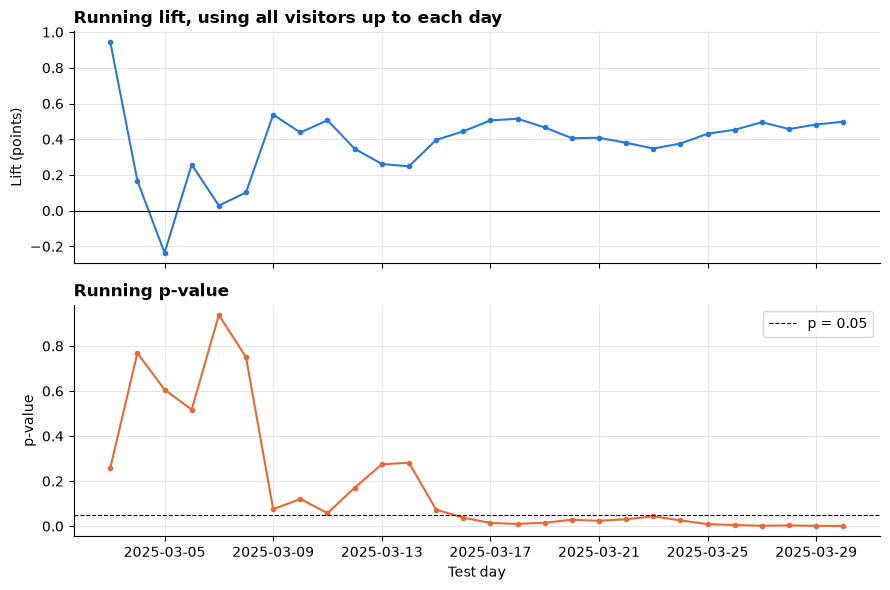

First day with p below 0.05: 2025-03-16


In [17]:
days = sorted(ab["date"].unique())
running = []
for d in days:
    so_far = ab[ab["date"] <= d]
    g = so_far.groupby("variant").agg(visitors=("converted", "size"), buyers=("converted", "sum"))
    r = compare_rates(g.loc["A", "buyers"], g.loc["A", "visitors"], g.loc["B", "buyers"], g.loc["B", "visitors"])
    running.append({"date": d, "lift (points)": r["lift"] * 100, "p_value": r["p_value"]})
running = pd.DataFrame(running).set_index("date")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(running.index, running["lift (points)"], marker="o", markersize=3)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_title("Running lift, using all visitors up to each day")
ax1.set_ylabel("Lift (points)")
ax2.plot(running.index, running["p_value"], marker="o", markersize=3, color="#eb6834")
ax2.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="p = 0.05")
ax2.set_title("Running p-value")
ax2.set_ylabel("p-value")
ax2.set_xlabel("Test day")
ax2.legend()
fig.tight_layout()
plt.show()

first = running[running["p_value"] < 0.05]
print("First day with p below 0.05:", first.index[0].date() if len(first) else "none")

The real test has a genuine effect built in, so the peeker gets the right direction here. The problem is the **rule**. To see it, run **A/A tests**: shuffle the variant labels so there is **no** real difference, and count how often the peeker's rule still declares a winner.

> **Your turn:** change the code in the next cell and run it again.

In [18]:
# 1. Run the cell. What share of A/A tests produce a false winner when checked once at the end? When checked daily?
# 2. Change check_every to 7 (a weekly check). What happens to the false-winner share?
# 3. Explain to the colleague, in two sentences, why stopping at the first significant day misleads.
check_every = 1
aa_tests = 500

rng = np.random.default_rng(seed=1)
day = (ab["date"] - ab["date"].min()).dt.days.to_numpy()
converted = ab["converted"].to_numpy()
is_b = (ab["variant"] == "B").to_numpy()
looks = np.arange(check_every - 1, day.max() + 1, check_every)


def running_z(labels):
    vb = np.cumsum(np.bincount(day[labels], minlength=day.max() + 1))
    va = np.cumsum(np.bincount(day[~labels], minlength=day.max() + 1))
    bb = np.cumsum(np.bincount(day[labels], weights=converted[labels], minlength=day.max() + 1))
    ba = np.cumsum(np.bincount(day[~labels], weights=converted[~labels], minlength=day.max() + 1))
    pooled = (ba + bb) / (va + vb)
    return (bb / vb - ba / va) / np.sqrt(pooled * (1 - pooled) * (1 / va + 1 / vb))


z = np.array([running_z(rng.permutation(is_b)) for _ in range(aa_tests)])
print(f"Looks per test: {len(looks)}")
print(f"False winners, one look at the end:      {(np.abs(z[:, -1]) > 1.96).mean():.1%}")
print(f"False winners, stop at first p below 0.05: {(np.abs(z[:, looks]) > 1.96).any(axis=1).mean():.1%}")

Looks per test: 28
False winners, one look at the end:      4.8%
False winners, stop at first p below 0.05: 26.4%


> **Hint**
>
> A 5% false-alarm rate is a promise about **one** look. Every extra look is another chance for noise to cross the line. Also think about the size of the lift on the day a peeker stops: is it more likely to be too big or too small?

### C2 (Challenge): Slicing until something wins

Another colleague slices the result:

> *"B works on mobile but does nothing on desktop, so roll it out to mobile only. And when I split the results by device and day, a few days came out significant, so the effect comes and goes."*

First, the two device subgroups, each with its own interval.

In [19]:
rows = {}
for device, part in ab.groupby("device"):
    g = part.groupby("variant").agg(visitors=("converted", "size"), buyers=("converted", "sum"))
    r = compare_rates(g.loc["A", "buyers"], g.loc["A", "visitors"], g.loc["B", "buyers"], g.loc["B", "visitors"])
    rows[device] = {"visitors": f"{len(part):,}", "lift (points)": f"{r['lift'] * 100:+.2f}",
                    "95% CI (points)": f"{r['low'] * 100:+.2f} to {r['high'] * 100:+.2f}",
                    "p-value": f"{r['p_value']:.4f}"}
pd.DataFrame(rows).T

,visitors,lift (points),95% CI (points),p-value
desktop,"22,650",+0.30,-0.23 to +0.83,0.2680
mobile,"37,350",+0.62,+0.28 to +0.95,0.0003


Now every **device × day** slice: 2 devices × 28 days = 56 small tests. Count the "significant" ones, then see how many an A/A test (no real effect) produces.

> **Your turn:** change the code in the next cell and run it again.

In [20]:
# 1. Run the cell. How many of the 56 slices are "significant"? In which direction?
# 2. How many significant slices does an A/A test give on average, with no real effect at all?
# 3. Change slice_by to "device" only (edit the list). Which conclusions survive?
slice_by = ["device", "date"]

slices = ab.groupby(slice_by + ["variant"]).agg(visitors=("converted", "size"), buyers=("converted", "sum")).unstack("variant")
slice_p = [compare_rates(row[("buyers", "A")], row[("visitors", "A")], row[("buyers", "B")], row[("visitors", "B")])
           for _, row in slices.iterrows()]
lifts = np.array([r["lift"] for r in slice_p])
pvals = np.array([r["p_value"] for r in slice_p])
print(f"Slices: {len(slice_p)} | significant with B ahead: {((pvals < 0.05) & (lifts > 0)).sum()}"
      f" | significant with A ahead: {((pvals < 0.05) & (lifts < 0)).sum()}")

rng = np.random.default_rng(seed=1)
key = ab.groupby(slice_by).ngroup().to_numpy()
n_slices = key.max() + 1
aa_counts = []
for _ in range(500):
    lab = rng.permutation(is_b)
    vb, va = np.bincount(key[lab], minlength=n_slices), np.bincount(key[~lab], minlength=n_slices)
    bb = np.bincount(key[lab], weights=converted[lab], minlength=n_slices)
    ba = np.bincount(key[~lab], weights=converted[~lab], minlength=n_slices)
    pooled = (ba + bb) / (va + vb)
    with np.errstate(divide="ignore", invalid="ignore"):
        zz = (bb / vb - ba / va) / np.sqrt(pooled * (1 - pooled) * (1 / va + 1 / vb))
    aa_counts.append((np.abs(zz) > 1.96).sum())
print(f"A/A tests: average significant slices {np.mean(aa_counts):.1f} of {n_slices}; "
      f"at least one in {np.mean(np.array(aa_counts) > 0):.0%} of tests")

Slices: 56 | significant with B ahead: 6 | significant with A ahead: 0
A/A tests: average significant slices 2.7 of 56; at least one in 97% of tests


Answer in your evidence log:

1. The desktop interval includes zero. Does that show the page "does nothing on desktop"? Does the desktop interval also include the mobile lift? What can you honestly say?
2. Compare the number of significant device × day slices with what A/A tests produce by chance. Is "the desktop effect comes and goes" a finding?
3. Rewrite the colleague's message so it is accurate. Say what a follow-up test would need to show to support a mobile-only roll-out.

> **Hint**
>
> "Not significant" means "not shown", not "shown to be zero". A subgroup has fewer visitors, so its interval is wider. And 56 slices give noise 56 chances.

---

## Validation checklist

- [ ] AOV was computed on **orders** (lines added up per order), not on lines.
- [ ] The sampling distribution is centred near the true AOV, and its SE roughly matches SD ÷ √n.
- [ ] The bootstrap and formula intervals were both reported, with units, and read correctly.
- [ ] The A/B test has one row per visitor, about half in each group, and a similar device mix in A and B.
- [ ] Conversion and revenue per visitor divide by **all** visitors in the group.
- [ ] Lifts state whether they are **percentage points** or **percent**.
- [ ] Every lift has a 95% interval; the p-value is explained in plain words.
- [ ] Subgroup and slice results are labelled as exploratory, with their own intervals.

---

## Exit ticket

1. Why must you add up order lines before computing average order value?
2. What does a 95% confidence interval for AOV mean, in one sentence a manager would understand?
3. Your sample becomes four times bigger. What happens to the standard error?
4. The conversion lift is +0.5 percentage points with a 95% interval that excludes zero. Name one more thing you would check before recommending a roll-out.
5. Why does checking a test every day and stopping at the first p < 0.05 produce too many false winners?

---

## Evidence to keep

- [ ] Your G4 interval for AOV and the two-sentence explanation for the retail lead (G5)
- [ ] The balance check (I1) and the A/B results table with lift, interval and p-value (I2–I4)
- [ ] Your three-sentence manager summary of the A/B test (I5)
- [ ] Optional: the sample-size chart (I7) and your peeking or slicing explanation (C1–C2)